MMA3001 Project – Reconstruction of Missing Environmental Sensor Data
Project aim
Copare linera interpolaton and cubic spline interpolation for reconstructing missing environmental sensor measurements.
Variables analysed:
- Tempeature
- Humidity
- Carbon dioxide
- Pressure
Main analyses:
1. Data loading and JSON parsing
2. Duplicate removal and sensor selection
3. 10% random missing-data comparison
4. Missing-data sensitivity
5. Continuous sensor-outage sensitivity
6. Runtime comparison
7. Final method comparison
The selected primary sensor is 6012002000326, because it contains the largest number of useful unique readings in the supplied dataset.

In [1]:
# These libraries help us read data, do maths, make graphs and measure errors.
# We use SciPy to draw the cuibc curves for the missing readings.

import pandas as pd
import numpy as np
import json
import time
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error

from scipy.interpolate import CubicSpline


2. Load the raw CSV datsset
The supplied CSV contains some malformed rows and non-UTF-8 characters.
The Python parser is therefore used with latin1 encdoing and malformed rows are skipped.

In [2]:
# Load the CSV file that contains the sennsor data.
# Print its size and column names so we can check it loaded properly.

file_path = "5EnvSensor_MayToDec2024_180kRows.csv"

df = pd.read_csv(
    file_path,
    engine="python",
    encoding="latin1",
    on_bad_lines="skip"
)

print("Raw shape:", df.shape)
print(df.columns)
df.head()

Raw shape: (179447, 8)
Index(['id', 'sensorid', 'devicetype', 'jsondata', 'status',
       'processing_errors', 'createdate', 'processdate'],
      dtype='str')


,id,sensorid,devicetype,jsondata,status,processing_errors,createdate,processdate
0,2,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 03:11:58.210358+11,2024-02-29 03:11:58.210358+11
1,4,6012002000241,env,"[{""values"": [{""time"": 1702273965, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:08.833822+11,2024-02-29 17:09:08.833822+11
2,5,6012002000326,env,"[{""values"": [{""time"": 1702270857, ""value"": 4.1...",Processed,NaN,2024-02-29 17:09:12.444245+11,2024-02-29 17:09:12.444245+11
3,16,6012002000777,env,"[{""values"": [{""time"": 1683326565, ""value"": 4.1...",Processed,NaN,2024-02-29 17:10:24.443407+11,2024-02-29 17:10:24.443407+11
4,24,6012002000869,env,"[{""values"": [{""time"": 1709186696, ""value"": 4.1...",Processed,NaN,2024-02-29 17:11:11.348578+11,2024-02-29 17:11:11.348578+11


3. Parse the JSON sensor measurements
The useful measurements are stored inside the jsondata column.
This section converts the JSON records into a normal table conaining sensor ID, varialbe, unit, timestamp and value.

In [3]:
# The CSV stores readings inside JSON text, so we unpack it into individual rows.
# We also turn the recorded timrs into dates Python can work with.

records = []

for _, row in df.iterrows():
    try:
        measurements = json.loads(row["jsondata"])
    except (TypeError, json.JSONDecodeError):
        continue

    for measurement in measurements:
        variable = measurement.get("variable", {})

        for reading in measurement.get("values", []):
            records.append({
                "sensorid": row["sensorid"],
                "variable": variable.get("name"),
                "unit": variable.get("unit"),
                "structure": variable.get("structure"),
                "time": reading.get("time"),
                "value": reading.get("value")
            })

sensor_data = pd.DataFrame(records)

sensor_data["datetime"] = pd.to_datetime(
    sensor_data["time"],
    unit="s",
    utc=True,
    errors="coerce"
)

sensor_data["sensorid"] = pd.to_numeric(
    sensor_data["sensorid"],
    errors="coerce"
).astype("Int64")

print("Parsed shape:", sensor_data.shape)
print(sensor_data.dtypes)

sensor_data.head()


Parsed shape: (1937515, 7)
sensorid                   Int64
variable                     str
unit                         str
structure                  int64
time                       int64
value                    float64
datetime     datetime64[us, UTC]
dtype: object


,sensorid,variable,unit,structure,time,value,datetime
0,6012002000241,Battery,V,32834,1702273965,4.1875,2023-12-11 05:52:45+00:00
1,6012002000241,Carbon dioxide,ppm,32835,1702273965,603.0000,2023-12-11 05:52:45+00:00
2,6012002000241,Humidity,HR%,32840,1702273965,66.0000,2023-12-11 05:52:45+00:00
3,6012002000241,Formaldehyde,Âµg/m3,32847,1702273965,6.0000,2023-12-11 05:52:45+00:00
4,6012002000241,Pressure,mb,32848,1702273965,1011.0000,2023-12-11 05:52:45+00:00


4. Inspect sensors and unqiue readings
The source contains repeated historical records, so duplicate measurements must be removed before analysis.

In [4]:
# Count how many different readings each sensor has.
# This helps us choose a sensor with enough data for testing.

unique_counts = (
    sensor_data
    .drop_duplicates(
        subset=["sensorid", "variable", "datetime", "value"]
    )
    .groupby(["sensorid", "variable"])
    .size()
    .reset_index(name="unique_readings")
)

unique_counts.sort_values(
    "unique_readings",
    ascending=False
).head(50)


,sensorid,variable,unique_readings
24,6012002000326,Formaldehyde,29040
31,6012002000326,Pressure,29039
22,6012002000326,Battery,29039
26,6012002000326,Light Volatile Organic Compounds,29039
25,6012002000326,Humidity,29039
23,6012002000326,Carbon dioxide,29039
32,6012002000326,Temperature,29039
28,6012002000326,Particulate matter 10,27346
27,6012002000326,Particulate matter 1,27346
29,6012002000326,Particulate matter 2.5,27346


Sensor selection
Sensor 6012002000326 is selected because it contains approximately 29,000 unique readings for each of the main environmental variables.
The project uses:
- Temperature
- Humidity
- Carbon dioxide
- Pressure

In [5]:
# Focuus on one sensor and the four measurements we want to compare.
# Sort the readings by time and remove identical copies.

SENSOR_ID = 6012002000326

variables_to_use = [
    "Temperature",
    "Humidity",
    "Carbon dioxide",
    "Pressure"
]

selected_data = sensor_data[
    (sensor_data["sensorid"] == SENSOR_ID) &
    (sensor_data["variable"].isin(variables_to_use))
].copy()

selected_data = selected_data.drop_duplicates(
    subset=["sensorid", "variable", "datetime", "value"]
)

selected_data = selected_data.sort_values(
    ["variable", "datetime"]
).reset_index(drop=True)

selected_data.groupby("variable").size()


variable
Carbon dioxide    29039
Humidity          29039
Pressure          29039
Temperature       29039
dtype: int64

5.1 Restrict analysis to the continuous operating period

In [6]:
# Check how many readings we have in each month.
# This helps show whether there are big gaps in the dataset.

monthly_counts = (
    selected_data
    .set_index("datetime")
    .groupby("variable")
    .resample("ME")
    .size()
    .reset_index(name="count")
)

for variable in variables_to_use:
    print("\n", variable)

    display(
        monthly_counts[
            monthly_counts["variable"] == variable
        ][["datetime", "count"]]
    )


 Temperature


,datetime,count
87,2023-12-31 00:00:00+00:00,1
88,2024-01-31 00:00:00+00:00,0
89,2024-02-29 00:00:00+00:00,0
90,2024-03-31 00:00:00+00:00,0
91,2024-04-30 00:00:00+00:00,0
92,2024-05-31 00:00:00+00:00,0
93,2024-06-30 00:00:00+00:00,0
94,2024-07-31 00:00:00+00:00,0
95,2024-08-31 00:00:00+00:00,0
96,2024-09-30 00:00:00+00:00,0



 Humidity


,datetime,count
29,2023-12-31 00:00:00+00:00,1
30,2024-01-31 00:00:00+00:00,0
31,2024-02-29 00:00:00+00:00,0
32,2024-03-31 00:00:00+00:00,0
33,2024-04-30 00:00:00+00:00,0
34,2024-05-31 00:00:00+00:00,0
35,2024-06-30 00:00:00+00:00,0
36,2024-07-31 00:00:00+00:00,0
37,2024-08-31 00:00:00+00:00,0
38,2024-09-30 00:00:00+00:00,0



 Carbon dioxide


,datetime,count
0,2023-12-31 00:00:00+00:00,1
1,2024-01-31 00:00:00+00:00,0
2,2024-02-29 00:00:00+00:00,0
3,2024-03-31 00:00:00+00:00,0
4,2024-04-30 00:00:00+00:00,0
5,2024-05-31 00:00:00+00:00,0
6,2024-06-30 00:00:00+00:00,0
7,2024-07-31 00:00:00+00:00,0
8,2024-08-31 00:00:00+00:00,0
9,2024-09-30 00:00:00+00:00,0



 Pressure


,datetime,count
58,2023-12-31 00:00:00+00:00,1
59,2024-01-31 00:00:00+00:00,0
60,2024-02-29 00:00:00+00:00,0
61,2024-03-31 00:00:00+00:00,0
62,2024-04-30 00:00:00+00:00,0
63,2024-05-31 00:00:00+00:00,0
64,2024-06-30 00:00:00+00:00,0
65,2024-07-31 00:00:00+00:00,0
66,2024-08-31 00:00:00+00:00,0
67,2024-09-30 00:00:00+00:00,0


In [7]:
# Check the daets covered by the measurements and keep the main study period.
# Remove invalid values and combine readings tkaen at the same time.

monthly_counts = (
    selected_data
    .set_index("datetime")
    .groupby("variable")
    .resample("ME")
    .size()
    .reset_index(name="count")
)

for variable in variables_to_use:
    print("\n", variable)

    display(
        monthly_counts[
            monthly_counts["variable"] == variable
        ][["datetime", "count"]]
    )
date_summary = (
    selected_data
    .groupby("variable")
    .agg(
        first_reading=("datetime", "min"),
        last_reading=("datetime", "max"),
        total_readings=("value", "count")
    )
)
analysis_data = selected_data[
    selected_data["datetime"] >= "2025-09-01"
].copy()

# Clean non-numeric measurements and repeated timestamps befpre interpolation.
analysis_data["value"] = pd.to_numeric(analysis_data["value"], errors="coerce")
analysis_data = analysis_data.dropna(subset=["datetime", "value"])
analysis_data = analysis_data[np.isfinite(analysis_data["value"])].copy()
duplicate_rows = analysis_data.duplicated(["variable", "datetime"], keep=False).sum()
print(f"Repeated timestamp rows (before averaging): {duplicate_rows}")
# One sensor is srlected, so one reading per variable and timestamp is required.
analysis_data = (analysis_data.groupby(["variable", "datetime"], as_index=False, sort=False)
                 .agg(value=("value", "mean")))

analysis_data = analysis_data.sort_values(
    ["variable", "datetime"]
).reset_index(drop=True)

print("Analysis data counts:")
print(analysis_data.groupby("variable").size())

print("\nAnalysis date range:")
print(
    analysis_data.groupby("variable").agg(
        first_reading=("datetime", "min"),
        last_reading=("datetime", "max")
    )
)

date_summary


 Temperature


,datetime,count
87,2023-12-31 00:00:00+00:00,1
88,2024-01-31 00:00:00+00:00,0
89,2024-02-29 00:00:00+00:00,0
90,2024-03-31 00:00:00+00:00,0
91,2024-04-30 00:00:00+00:00,0
92,2024-05-31 00:00:00+00:00,0
93,2024-06-30 00:00:00+00:00,0
94,2024-07-31 00:00:00+00:00,0
95,2024-08-31 00:00:00+00:00,0
96,2024-09-30 00:00:00+00:00,0



 Humidity


,datetime,count
29,2023-12-31 00:00:00+00:00,1
30,2024-01-31 00:00:00+00:00,0
31,2024-02-29 00:00:00+00:00,0
32,2024-03-31 00:00:00+00:00,0
33,2024-04-30 00:00:00+00:00,0
34,2024-05-31 00:00:00+00:00,0
35,2024-06-30 00:00:00+00:00,0
36,2024-07-31 00:00:00+00:00,0
37,2024-08-31 00:00:00+00:00,0
38,2024-09-30 00:00:00+00:00,0



 Carbon dioxide


,datetime,count
0,2023-12-31 00:00:00+00:00,1
1,2024-01-31 00:00:00+00:00,0
2,2024-02-29 00:00:00+00:00,0
3,2024-03-31 00:00:00+00:00,0
4,2024-04-30 00:00:00+00:00,0
5,2024-05-31 00:00:00+00:00,0
6,2024-06-30 00:00:00+00:00,0
7,2024-07-31 00:00:00+00:00,0
8,2024-08-31 00:00:00+00:00,0
9,2024-09-30 00:00:00+00:00,0



 Pressure


,datetime,count
58,2023-12-31 00:00:00+00:00,1
59,2024-01-31 00:00:00+00:00,0
60,2024-02-29 00:00:00+00:00,0
61,2024-03-31 00:00:00+00:00,0
62,2024-04-30 00:00:00+00:00,0
63,2024-05-31 00:00:00+00:00,0
64,2024-06-30 00:00:00+00:00,0
65,2024-07-31 00:00:00+00:00,0
66,2024-08-31 00:00:00+00:00,0
67,2024-09-30 00:00:00+00:00,0


Repeated timestamp rows (before averaging): 0
Analysis data counts:
variable
Carbon dioxide    29038
Humidity          29038
Pressure          29038
Temperature       29038
dtype: int64

Analysis date range:
                           first_reading              last_reading
variable                                                          
Carbon dioxide 2025-09-07 10:09:30+00:00 2026-04-22 13:12:41+00:00
Humidity       2025-09-07 10:09:30+00:00 2026-04-22 13:12:41+00:00
Pressure       2025-09-07 10:09:30+00:00 2026-04-22 13:12:41+00:00
Temperature    2025-09-07 10:09:30+00:00 2026-04-22 13:12:41+00:00


,first_reading,last_reading,total_readings
variable,,,
Carbon dioxide,2023-12-11 05:00:57+00:00,2026-04-22 13:12:41+00:00,29039
Humidity,2023-12-11 05:00:57+00:00,2026-04-22 13:12:41+00:00,29039
Pressure,2023-12-11 05:00:57+00:00,2026-04-22 13:12:41+00:00,29039
Temperature,2023-12-11 05:00:57+00:00,2026-04-22 13:12:41+00:00,29039


5. Plot the cleaned time series

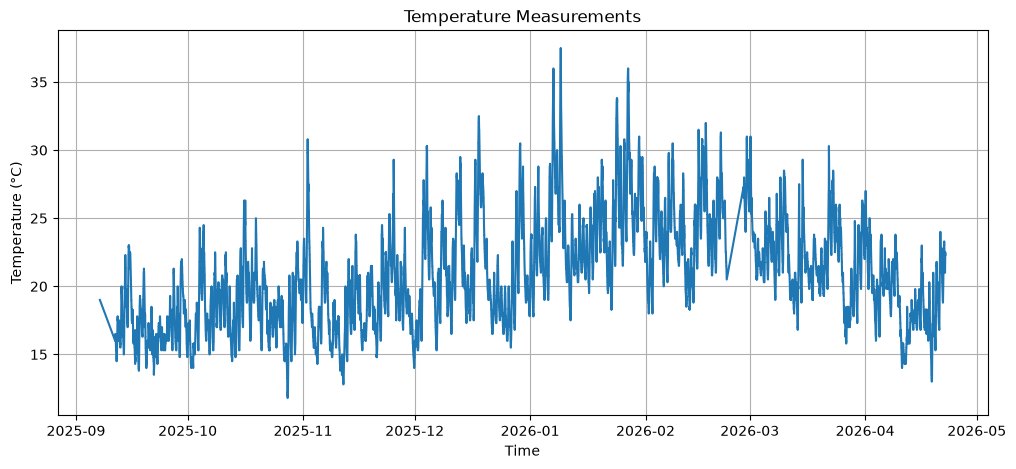

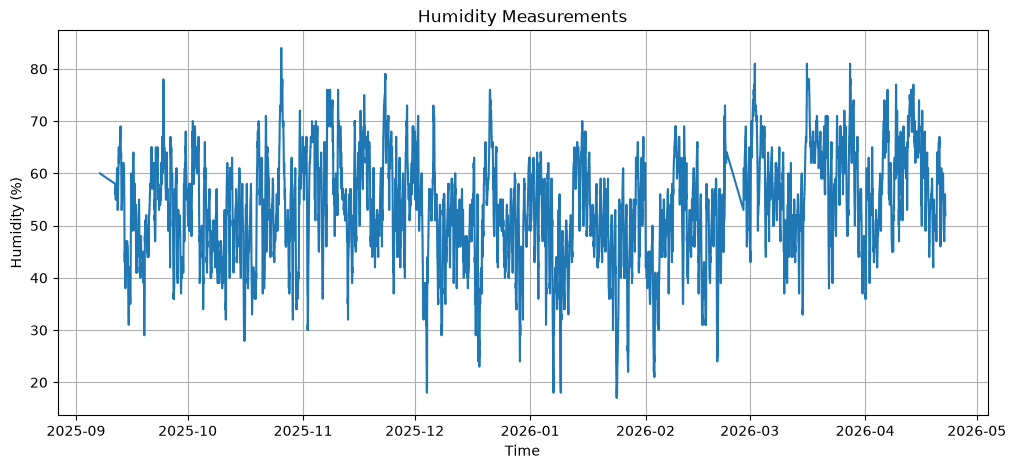

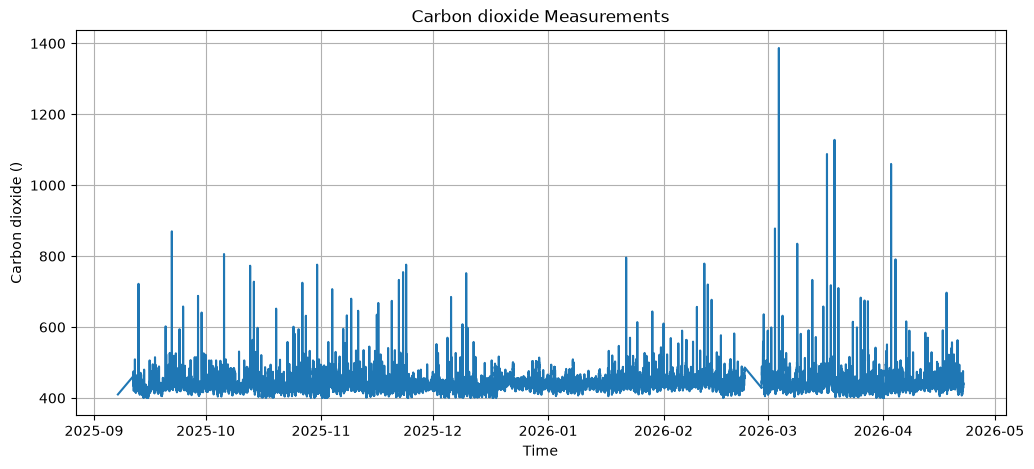

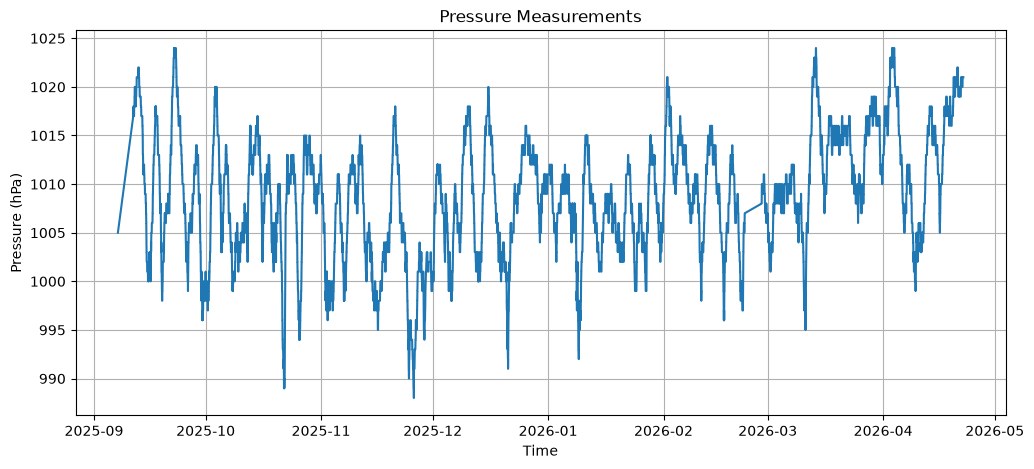

In [9]:
# Draw each sensor variable over time to see what the raw data looks like.

for variable in variables_to_use:
    subset = analysis_data[
        analysis_data["variable"] == variable
    ].copy()

    if subset.empty:
        print(f"Skipping {variable}: no data found")
        continue

    units = {
    "temperature": "°C",
    "humidity": "%",
    "co2": "ppm",
    "pressure": "hPa"
    }

    unit = units.get(str(variable).lower(), "")

    plt.figure(figsize=(12, 5))
    plt.plot(subset["datetime"], subset["value"])

    plt.xlabel("Time")
    plt.ylabel(f"{variable} ({unit})")
    plt.title(f"{variable} Measurements")
    plt.grid()

    plt.show()


6. Baseline Interpolation Comparison

In [10]:
# These functions fill in missing readings from the known measurements.
# First we check the inputs, then use either a straight line or a cubic curve.

def prepare_interpolation(values, timestamps):
    """Convert sensor values/timestamps into validated numeric arrays.

    Parameters
    ----------
    values : array-like
        Sensor values, using NaN for missing measurements.
    timestamps : array-like
        UTC or consistently timezone-aware timestamps in increasing order.

    Returns
    -------
    tuple of numpy.ndarray
        (elapsed seconds from first measurement, sensor values, finite mask).

    Raises
    ------
    ValueError
        If data lengths mismatch, timestamps repeat/decrease, or time is invalid.
    """
    # Turn sensor readings into numbers we can calculste with.
    y = np.asarray(values, dtype=float)
    # Turn the measurement times into a consistent date/time format.
    dt = pd.DatetimeIndex(timestamps)
    if len(y) != len(dt) or not len(y):
        raise ValueError("Sensor values and timestamps must have equal nonzero lengths")
    if dt.hasnans:
        raise ValueError("Timestamps must not contain NaT")
    # Convert integer nanoseconds to secnds relative to the start to avoid
    # precision loss from large Unix timestamps.
    # Work out secpnds since the first reading, so gaps use real time.
    x = (dt.asi8 - dt.asi8[0]).astype(np.float64) / 1e9
    if not np.all(np.diff(x) > 0):
        raise ValueError("Timestamps must be unique and strictly increasing")
    return x, y, np.isfinite(y)


def linear_interpolation(values, timestamps):
    """Reconstruct missing sensor readings by linear interpolation in time.

    Requires at least two known readings. Known values remain unchanged.
    This project prevents missing endpoints; no extrapolation is intended.
    """
    x, y, known = prepare_interpolation(values, timestamps)
    if known.sum() < 2 or not known[0] or not known[-1]:
        raise ValueError("Linear interpolation needs two known values and known endpoints")
    out = y.copy()
    missing = ~known
    out[missing] = np.interp(x[missing], x[known], y[known])
    return out


def cubic_interpolation(values, timestamps):
    """Reconstruct missing readings with a cubic *interpolating* spline.

    Fits a SciPy CubicSpline through known values on the time axis and
    predicts only missing points. Requires >= 4 known values and known
    endpoints. Cubic splines can overshoot around sharp sensor changes.
    """
    x, y, known = prepare_interpolation(values, timestamps)
    if known.sum() < 4 or not known[0] or not known[-1]:
        raise ValueError("Cubic spline needs four known values and known endpoints")
    out = y.copy()
    missing = ~known
    if missing.any():
        model = CubicSpline(x[known], y[known], bc_type="not-a-knot")
        out[missing] = model(x[missing])
    return out


**Method update:** Both interpolators use elapsed seconds from recorded timestamps. The spline uses `scipy.interpolate.CubicSpline` and passes through known values. Therefore outputs are not directly comparable with the previpus pandas smoothing-spline experiment.

In [11]:
# This experiment tets how well both methosd can guess hiddne sensor readings.
# We keep the actual answers, hide some values, then measure the difference.

def test_interpolation(
    data,
    variable_name,
    remove_fraction=0.10,
    seed=42
):
    # Select one environmental variable
    subset = data[
        data["variable"] == variable_name
    ].copy()

    # Sort measurements chronologically
    subset = subset.sort_values(
        "datetime"
    ).reset_index(drop=True)

    # Keep an untouched copy of the real measurements
    subset["original"] = subset["value"]

    # Reproducible random number generator
    # Same seed means we can repeat the exact same random test.
    rng = np.random.default_rng(seed)

    # Determine number of readings to remove
    n_remove = int(
        len(subset) * remove_fraction
    )

    # Do not remove the first or last value because
    # interpolation requires values on both sides
    remove_indices = rng.choice(
        subset.index[1:-1],
        size=n_remove,
        replace=False
    )

    # Artfiicially create missing measurements
    subset.loc[
        remove_indices,
        "value"
    ] = np.nan

    # Both methods operate on actual elapsed time, using identical missng points.
    subset["linear"] = linear_interpolation(subset["value"], subset["datetime"])
    subset["spline"] = cubic_interpolation(subset["value"], subset["datetime"])

    # Actual valuues that were deliberately rmoved
    actual = subset.loc[
        remove_indices,
        "original"
    ]

    # Reeconstructed values
    linear_pred = subset.loc[
        remove_indices,
        "linear"
    ]

    spline_pred = subset.loc[
        remove_indices,
        "spline"
    ]

    # Calculate errors
    linear_mae = mean_absolute_error(
        actual,
        linear_pred
    )

    linear_rmse = np.sqrt(
        mean_squared_error(
            actual,
            linear_pred
        )
    )

    spline_mae = mean_absolute_error(
        actual,
        spline_pred
    )

    spline_rmse = np.sqrt(
        mean_squared_error(
            actual,
            spline_pred
        )
    )

    return {
        "Variable": variable_name,
        "Linear MAE": linear_mae,
        "Linear RMSE": linear_rmse,
        "Spline MAE": spline_mae,
        "Spline RMSE": spline_rmse
    }

In [12]:
# Run the main test for each of the four measurements.
# Put the results together in one table so they are easy to compare.

all_results = []

for variable in variables_to_use:

    result = test_interpolation(
        analysis_data,
        variable,
        remove_fraction=0.10,
        seed=42
    )

    all_results.append(result)

results_df = pd.DataFrame(
    all_results
)

results_df

,Variable,Linear MAE,Linear RMSE,Spline MAE,Spline RMSE
0,Temperature,0.071505,0.103206,0.093188,0.121483
1,Humidity,0.305053,0.466073,0.383303,0.525237
2,Carbon dioxide,7.346139,15.475032,9.359127,17.125910
3,Pressure,0.109121,0.258963,0.168886,0.313374


7. Missing Data Sensitivity analysis

In [13]:
# Repeat the test with different amounts of missing data.
# This shows whether the methods get worse when more readigns disappear.

missing_levels = [
    0.05,
    0.10,
    0.20,
    0.30
]

sensitivity_results = []

for variable in variables_to_use:

    for fraction in missing_levels:

        result = test_interpolation(
            analysis_data,
            variable,
            remove_fraction=fraction,
            seed=42
        )

        result["Missing %"] = (
            fraction * 100
        )

        sensitivity_results.append(
            result
        )

sensitivity_df = pd.DataFrame(
    sensitivity_results
)

sensitivity_df = sensitivity_df[
    [
        "Variable",
        "Missing %",
        "Linear MAE",
        "Linear RMSE",
        "Spline MAE",
        "Spline RMSE"
    ]
]

sensitivity_df

,Variable,Missing %,Linear MAE,Linear RMSE,Spline MAE,Spline RMSE
0,Temperature,5.0,0.072463,0.104479,0.093716,0.122074
1,Temperature,10.0,0.071505,0.103206,0.093188,0.121483
2,Temperature,20.0,0.075064,0.111060,0.097330,0.130009
3,Temperature,30.0,0.077616,0.112795,0.101865,0.136053
4,Humidity,5.0,0.302337,0.467823,0.386632,0.522256
5,Humidity,10.0,0.305053,0.466073,0.383303,0.525237
6,Humidity,20.0,0.326685,0.531193,0.409903,0.579508
7,Humidity,30.0,0.351176,0.579935,0.437231,0.638058
8,Carbon dioxide,5.0,7.689523,19.133458,9.459143,19.940350
9,Carbon dioxide,10.0,7.346139,15.475032,9.359127,17.125910


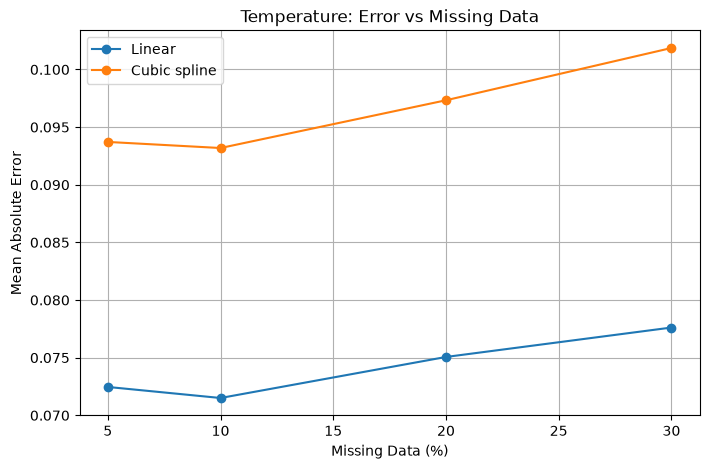

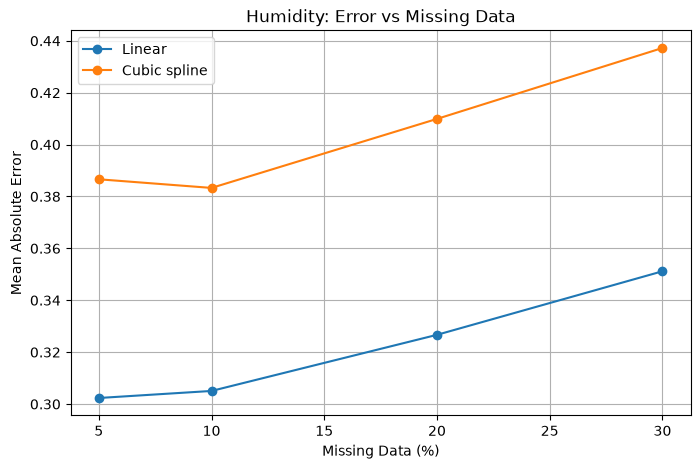

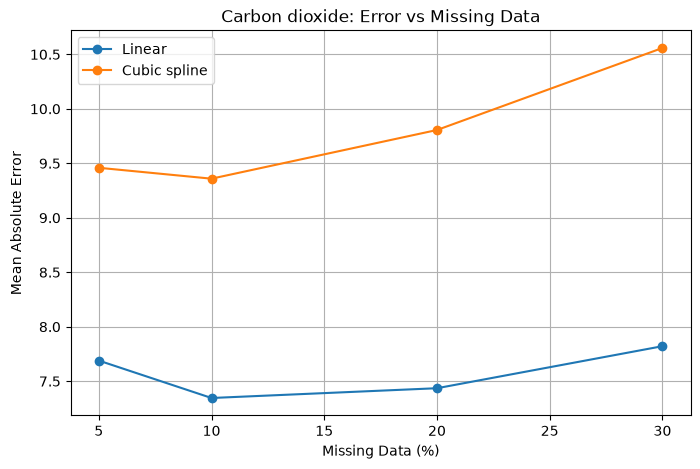

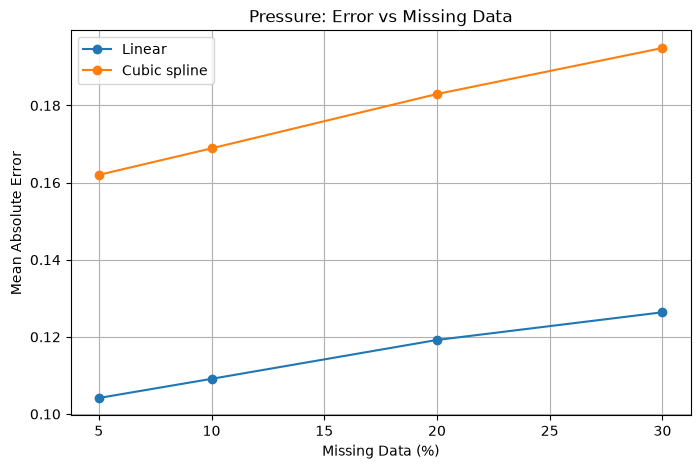

In [14]:
# Graph the errors at each missing-data percentage.
# A lower MAE means the methd is making smaller mistakes on average.

for variable in variables_to_use:

    subset = sensitivity_df[
        sensitivity_df["Variable"] == variable
    ]

    plt.figure(figsize=(8, 5))

    plt.plot(
        subset["Missing %"],
        subset["Linear MAE"],
        marker="o",
        label="Linear"
    )

    plt.plot(
        subset["Missing %"],
        subset["Spline MAE"],
        marker="o",
        label="Cubic spline"
    )

    plt.xlabel(
        "Missing Data (%)"
    )

    plt.ylabel(
        "Mean Absolute Error"
    )

    plt.title(
        f"{variable}: Error vs Missing Data"
    )

    plt.legend()
    plt.grid()

    plt.show()

### Interpretation

These results show how sensitive each interpolaton method is to an increasing proportion of missing measurements.

A method that maintains relatively low MAE as the peercentage of missimg data increases can be considered more robust for reconstructing isolated missing sensor measurements.

The final interpretation will be based on the measured results rather than assuming that the more complex interpolation method performs better.

## 8. Continuous snsor outage analysis

Random missing measurements represent isolated data loss, but a real sensor or communication failure may result in several consecutive readings being unavailable.

To represent this type of failure, continuous blocks of measurements are removed.

The following outage lnegths are investigated:

- 1 consecutive reading
- 5 consecutive readigns
- 10 consecutive readings
- 20 conseuctive readings

The location of an outage can significantly affect reconstruction difficulty. For example, an outage during a period of rapidly changing measurements may produce greatrr error than an outage during a stable period.

Therefore, each outage length is tested at 50 randomly selected positions within the dataset and the mean reconstruction errr is calculated.

In [15]:
# This test pretends the sensor stopped recording for a short period.
# We hide a group of readings in a row and repeat at diffetent locations.

def test_outage_average(
    data,
    variable_name,
    gap_length,
    repeats=50,
    seed=42
):
    # Select vriable
    subset = data[
        data["variable"] == variable_name
    ].copy()

    subset = subset.sort_values(
        "datetime"
    ).reset_index(drop=True)

    subset["original"] = (
        subset["value"]
    )

    rng = np.random.default_rng(
        seed
    )

    linear_maes = []
    linear_rmses = []

    spline_maes = []
    spline_rmses = []

    # Repeat the test so the result is not based on just one outage.
    for _ in range(repeats):

        test_data = subset.copy()

        # Select a random outage location
        max_start = (
            len(test_data)
            - gap_length
            - 1
        )

        start = rng.integers(
            1,
            max_start
        )

        gap_indices = np.arange(
            start,
            start + gap_length
        )

        # Remove consecutive readings
        test_data.loc[
            gap_indices,
            "value"
        ] = np.nan

        # Time-baded methods fitted on the SAME known measurements.
        test_data["linear"] = linear_interpolation(test_data["value"], test_data["datetime"])
        test_data["spline"] = cubic_interpolation(test_data["value"], test_data["datetime"])

        actual = test_data.loc[
            gap_indices,
            "original"
        ]

        linear_pred = test_data.loc[
            gap_indices,
            "linear"
        ]

        spline_pred = test_data.loc[
            gap_indices,
            "spline"
        ]

        # Stre error from this outage
        linear_maes.append(
            mean_absolute_error(
                actual,
                linear_pred
            )
        )

        linear_rmses.append(
            np.sqrt(
                mean_squared_error(
                    actual,
                    linear_pred
                )
            )
        )

        spline_maes.append(
            mean_absolute_error(
                actual,
                spline_pred
            )
        )

        spline_rmses.append(
            np.sqrt(
                mean_squared_error(
                    actual,
                    spline_pred
                )
            )
        )

    # Return mean performance across all outages
    return {
        "Variable": variable_name,
        "Gap Length": gap_length,

        "Linear MAE":
            np.mean(linear_maes),

        "Linear RMSE":
            np.mean(linear_rmses),

        "Spline MAE":
            np.mean(spline_maes),

        "Spline RMSE":
            np.mean(spline_rmses)
    }

In [16]:
# Try different outage lengths for each measurement.
# Average the results from repeated trials to reduce reliance on one random gap.

gap_lengths = [
    1,
    5,
    10,
    20
]

average_outage_results = []

for variable in variables_to_use:

    print(f"Testing {variable}...")

    for gap in gap_lengths:

        print(
            f"  Gap length: {gap}"
        )

        result = test_outage_average(
            analysis_data,
            variable,
            gap_length=gap,
            repeats=10,
            seed=42
        )

        average_outage_results.append(
            result
        )

average_outage_df = pd.DataFrame(
    average_outage_results
)

average_outage_df

Testing Temperature...
  Gap length: 1
  Gap length: 5
  Gap length: 10
  Gap length: 20
Testing Humidity...
  Gap length: 1
  Gap length: 5
  Gap length: 10
  Gap length: 20
Testing Carbon dioxide...
  Gap length: 1
  Gap length: 5
  Gap length: 10
  Gap length: 20
Testing Pressure...
  Gap length: 1
  Gap length: 5
  Gap length: 10
  Gap length: 20


,Variable,Gap Length,Linear MAE,Linear RMSE,Spline MAE,Spline RMSE
0,Temperature,1,0.060000,0.060000,0.071888,0.071888
1,Temperature,5,0.096954,0.110514,0.137339,0.154111
2,Temperature,10,0.154654,0.174242,0.181859,0.214683
3,Temperature,20,0.295047,0.336054,0.486557,0.560673
4,Humidity,1,0.283333,0.283333,0.369463,0.369463
5,Humidity,5,0.243333,0.319546,0.604853,0.676405
6,Humidity,10,0.600827,0.691527,1.264400,1.378076
7,Humidity,20,0.847241,0.977582,4.064047,4.585417
8,Carbon dioxide,1,5.016667,5.016667,6.384723,6.384723
9,Carbon dioxide,5,10.920491,12.341331,24.626817,27.533713


In [17]:
# Save the results as CSV tables so we can use them in the report.

average_outage_df.to_csv(
    "average_outage_results.csv",
    index=False
)
results_df.to_csv(
    "baseline_results.csv",
    index=False
)

sensitivity_df.to_csv(
    "sensitivity_results.csv",
    index=False
)



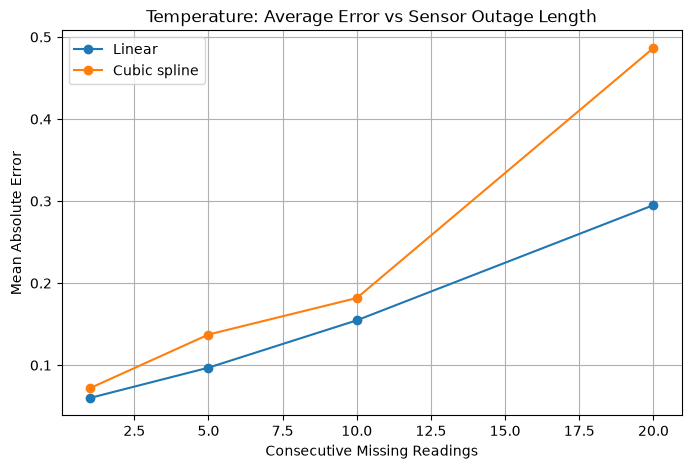

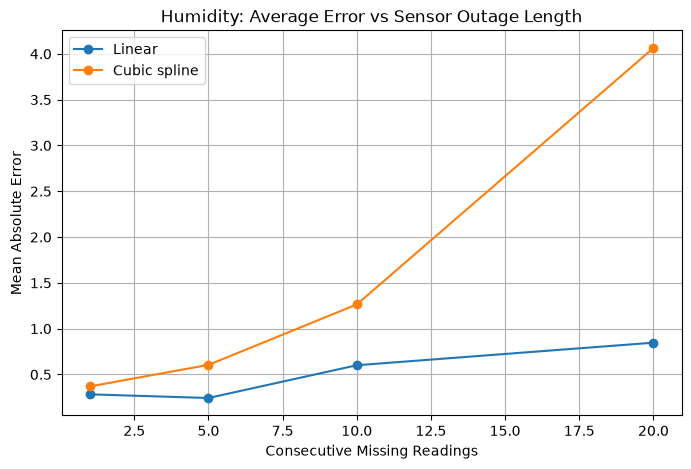

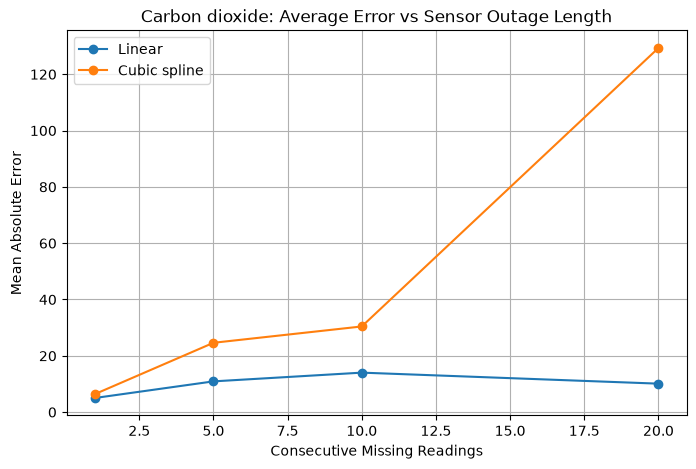

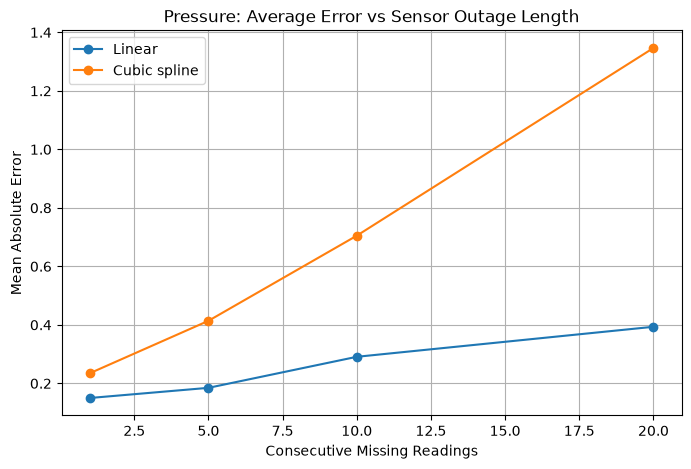

In [18]:
# Draw how the error changes as the gap becomes longer.

for variable in variables_to_use:

    subset = average_outage_df[
        average_outage_df["Variable"] == variable
    ]

    plt.figure(figsize=(8, 5))

    plt.plot(
        subset["Gap Length"],
        subset["Linear MAE"],
        marker="o",
        label="Linear"
    )

    plt.plot(
        subset["Gap Length"],
        subset["Spline MAE"],
        marker="o",
        label="Cubic spline"
    )

    plt.xlabel(
        "Consecutive Missing Readings"
    )

    plt.ylabel(
        "Mean Absolute Error"
    )

    plt.title(
        f"{variable}: Average Error vs Sensor Outage Length"
    )

    plt.legend()

    plt.grid()

    plt.show()

## 9. Computational runtime comparison

Interpolation accuracy is not the only consideration when selecting a numerical method. Computational efficiency may also be important when processing large environmental sensor datasets.

The execution time of linear and cuibc spline interpolation is therefore compared using the full continuous analysis dataset.

Each method is executed repeatedly and the median runtime is reported. The medoan is used because it is less affecetd by occasional unusually slow executions caused by background comuter processes.

In [19]:
# Check how much computing time each interpolation method needs.
# We time only the interpolation maths here, not the data loading.

def test_runtime(
    data,
    variable_name,
    repeats=20
):
    subset = data[
        data["variable"] == variable_name
    ].copy()

    subset = subset.sort_values(
        "datetime"
    ).reset_index(drop=True)

    rng = np.random.default_rng(42)

    # Create the same 10% missing-data condotion
    # used in the baseline comparison
    n_remove = int(
        len(subset) * 0.10
    )

    remove_indices = rng.choice(
        subset.index[1:-1],
        size=n_remove,
        replace=False
    )

    test_values = subset["value"].copy()

    test_values.loc[
        remove_indices
    ] = np.nan

    # Prepare time coordinates outsode timed region to benchmark the
    # interpolation algrithms, rather than pandas timestamp conversion.
    x, y, known = prepare_interpolation(test_values, subset["datetime"])
    missing = ~known
    x_known, y_known, x_missing = x[known], y[known], x[missing]

    # Warm-up
    np.interp(x_missing, x_known, y_known)
    CubicSpline(x_known, y_known)(x_missing)

    # Store the time for each trial, then compare typical runtimes.
    linear_times = []
    spline_times = []
    for _ in range(repeats):
        start = time.perf_counter()
        np.interp(x_missing, x_known, y_known)
        linear_times.append(time.perf_counter() - start)

        start = time.perf_counter()
        CubicSpline(x_known, y_known)(x_missing)
        spline_times.append(time.perf_counter() - start)

    return {
        "Variable": variable_name,

        "Linear Runtime (ms)":
            np.median(linear_times) * 1000,

        "Spline Runtime (ms)":
            np.median(spline_times) * 1000
    }

In [20]:
# Measure the runtime for each variable and collect the results.

runtime_results = []

for variable in variables_to_use:

    print(f"Testing runtime: {variable}")

    result = test_runtime(
        analysis_data,
        variable,
        repeats=10
    )

    runtime_results.append(result)

runtime_df = pd.DataFrame(
    runtime_results
)

runtime_df

Testing runtime: Temperature
Testing runtime: Humidity
Testing runtime: Carbon dioxide
Testing runtime: Pressure


,Variable,Linear Runtime (ms),Spline Runtime (ms)
0,Temperature,0.10295,0.82505
1,Humidity,0.10160,0.79395
2,Carbon dioxide,0.10185,0.85010
3,Pressure,0.10620,0.83230


In [21]:
# Save the timing resuts to a CSV file.

runtime_df.to_csv(
    "runtime_results.csv",
    index=False
)

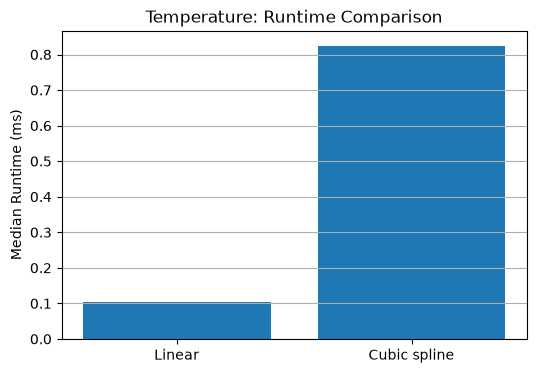

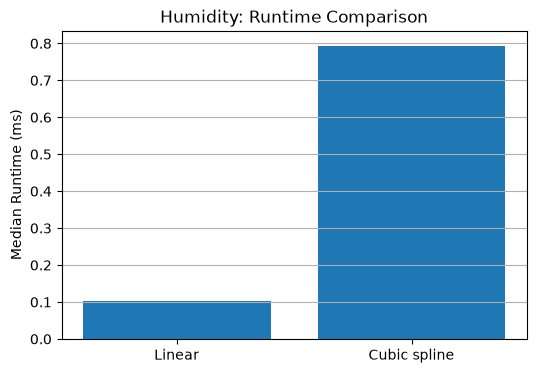

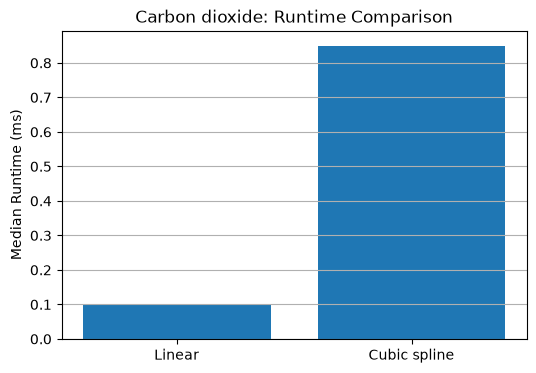

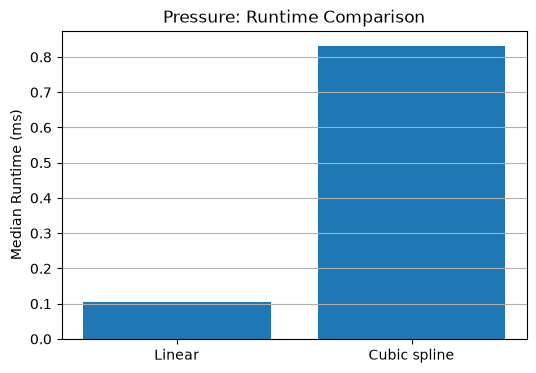

In [22]:
# Plot how long linear and cubic interpolation take.
# Lower bars mean the method ran faster in this test.

for variable in variables_to_use:

    subset = runtime_df[
        runtime_df["Variable"] == variable
    ]

    methods = [
        "Linear",
        "Cubic spline"
    ]

    runtimes = [
        subset[
            "Linear Runtime (ms)"
        ].iloc[0],

        subset[
            "Spline Runtime (ms)"
        ].iloc[0]
    ]

    plt.figure(figsize=(6, 4))

    plt.bar(
        methods,
        runtimes
    )

    plt.ylabel(
        "Median Runtime (ms)"
    )

    plt.title(
        f"{variable}: Runtime Comparison"
    )

    plt.grid(
        axis="y"
    )

    plt.show()

### Runtime interpretation (update after running)
The runtime table beolw benchmarks NumPy linear interpolation and SciPPy CubicSpline on the same time coordinates, excluding timestamp preprocessing. Discuss the measured times and relative runtime using the **new** output; previous pandas smoohting-spline timings are not comparable.

## 10. Final comparison and methdo selection

The two interpolation methods are compared using:

- Baseline reconstruction accuracy
- Sensitivity to increasing missing data
- Performance duing continuous sendor outages
- Computational runtime

The baseline 10% missing-data experiment is used to calculate the percentage improvement in MAE of linear interpolation reltive to cubic spline interpolation.

A positive percentage means linear interpolation producde lower reconstrction error.

In [23]:
# Compare the main errors and calculte how much lower linear MAE was.
# A positive improvement means linear interpolation had the loweer MAE.

final_summary = results_df.copy()

final_summary["MAE Improvement (%)"] = (
    (
        final_summary["Spline MAE"]
        - final_summary["Linear MAE"]
    )
    /
    final_summary["Spline MAE"]
) * 100

final_summary = final_summary[
    [
        "Variable",
        "Linear MAE",
        "Spline MAE",
        "Linear RMSE",
        "Spline RMSE",
        "MAE Improvement (%)"
    ]
]

final_summary

,Variable,Linear MAE,Spline MAE,Linear RMSE,Spline RMSE,MAE Improvement (%)
0,Temperature,0.071505,0.093188,0.103206,0.121483,23.268662
1,Humidity,0.305053,0.383303,0.466073,0.525237,20.414444
2,Carbon dioxide,7.346139,9.359127,15.475032,17.125910,21.508289
3,Pressure,0.109121,0.168886,0.258963,0.313374,35.388110


In [24]:
# Save the final compraison table for the report.

final_summary.to_csv(
    "final_summary.csv",
    index=False
)

### Method selection

The preferred interpolation method is selected by considering both numerical accuracy and computational performance.

If one method consistently produces lower MAE and RMSE, remains more robust as missing-data leevls and outage lengths increase, and also requires less computation time, it represents the stronger overall engineering choice.

The final conclusoon will therefore be based on the combined evidence from Sections 6 to 9 rather than on a single performance metric.

## 11. Engineering interpretation and final method selection — UPDATE AFTER RUNNING
Interpret the **new** baseline, sensitivity, outage and runtime results. Do not reuse percentages or conclusions from the old pandas smoothing spline. Select a method using both errr and exeution cost, and acknowledge any variables for which resylts differ.

### Limitations

Several limitations should be considered when interpreting tese results.

The analysis focuses on one environmental sensor, sensor `6012002000326`, and four measured variables: temperature, humidity, carbon dioxide and pressure.

The main analysis was restricted to the continuous monitoring period beginning in September 2025 because the dataset contained only a small numbre of isolated historical measurements before this period. Including these isolated measurements would have introduced unrealistic long-duration interpolation gaps.

The results therefore demonstrate the relative performance of linear and cubic spline interpolation for this specific sensor dataset and should not automatically be assumed to apply to all environmental monitoring systems.

The study also compares only two interpolation methods. Other approaches, including polynomial interpolation, nearest-neighbour reconstruction, time-series moddels or machine-learning methods, could be investigated in future work.

Finally, deliberately removing known measurements provides a controlled method of validation because the true values are available for comparison. However, real missing sensor data may occur undder operating conditions that differ from the randomly generated missing-data scenariso used in this study.

### Overall conclusion — UPDATE AFTER RUNNING
Summarise the newly computed results. The methods are now time-based linear interpolation and SciPy cubic *interpolating* spline (not the former pandas smoothing spline). Inclde limitations and engineering suitability.